# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 2: Image Exploration and Preprocessing

**Goals**
- Visualize sample images from all four categories (CNV, DME, DRUSEN, NORMAL)
- Analyze image dimensions, quality and variation
- Resize images to a consistent dimension
- Convert images to tensors
- Apply normalization and suitable augmentation



In [1]:
# Run once if torch / torchvision are not installed (CPU build is fine for this step)
%pip install -q torch torchvision datasets pillow matplotlib seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [3]:
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

sns.set_style("whitegrid")
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.15.0+cpu | CUDA available: False


In [4]:
dataset = load_dataset("zacharielegault/Kermany2017-OCT")
train_data = dataset["train"]
test_data = dataset["test"]

class_names = train_data.features["label"].names
train_labels = np.array(train_data["label"])      # read once, reuse below

print(dataset)
print("Classes:", class_names)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


## 2.1 Visualize sample images from all four categories
Random scans per class (rows), with each image's original size in the title.

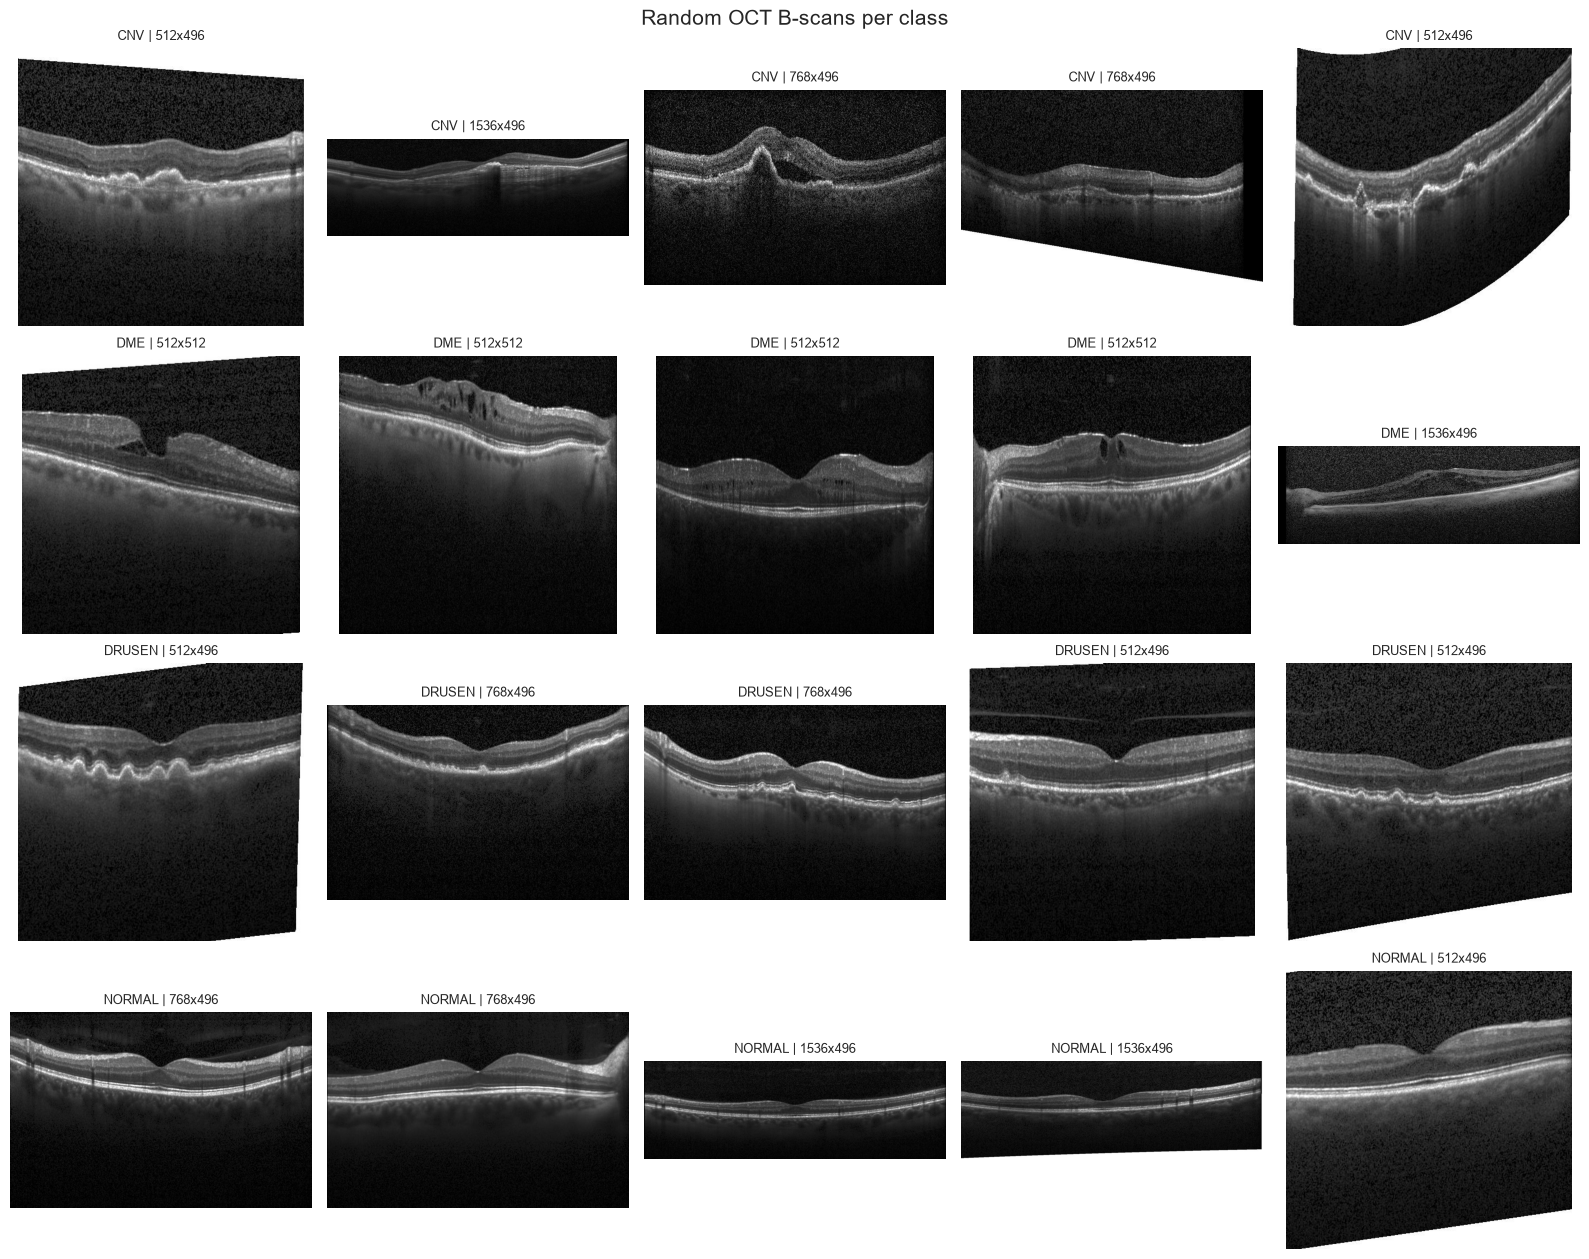

In [5]:
PER_CLASS = 5
fig, axes = plt.subplots(len(class_names), PER_CLASS, figsize=(3.2 * PER_CLASS, 3.2 * len(class_names)))

for r, cname in enumerate(class_names):
    picks = rng.choice(np.where(train_labels == r)[0], PER_CLASS, replace=False)
    for c, i in enumerate(picks):
        img = train_data[int(i)]["image"]
        ax = axes[r, c]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{cname} | {img.width}x{img.height}", fontsize=9)
        ax.axis("off")

plt.suptitle("Random OCT B-scans per class", fontsize=15)
plt.tight_layout()
plt.show()

** NORMAL scans show a smooth foveal dip with clean layers. CNV shows fluid or a bright membrane near the retinal pigment layer. 
DME shows cyst-like dark spaces and thickening. DRUSEN shows small bumps under the retina.

## 2.2 Analyze image dimensions, quality and variation
For a random sample of training images we measure size, aspect ratio, brightness, contrast, sharpness (variance of the Laplacian) and the fraction of near-black pixels.

In [6]:
def image_stats(img):
    arr = np.asarray(img.convert("L"), dtype=np.float32)
    lap = (4 * arr[1:-1, 1:-1] - arr[:-2, 1:-1] - arr[2:, 1:-1]
           - arr[1:-1, :-2] - arr[1:-1, 2:])
    return {
        "width": img.width,
        "height": img.height,
        "aspect": img.width / img.height,
        "mode": img.mode,
        "brightness": float(arr.mean()),
        "contrast": float(arr.std()),
        "sharpness": float(lap.var()),
        "dark_fraction": float((arr < 10).mean()),
    }

N_SAMPLE = 1200
sample_idx = rng.choice(len(train_data), N_SAMPLE, replace=False)

records = []
for i in sample_idx:
    rec = train_data[int(i)]
    row = image_stats(rec["image"])
    row["index"] = int(i)
    row["class"] = class_names[rec["label"]]
    records.append(row)

stats = pd.DataFrame(records)
print(f"Analysed {len(stats)} images")
display(stats[["width", "height", "aspect", "brightness", "contrast", "sharpness", "dark_fraction"]].describe().round(2))
print("Image modes:", stats["mode"].value_counts().to_dict())
print("\nWidth values:")
display(stats["width"].value_counts().rename_axis("width").reset_index(name="count").head(10))

Analysed 1200 images


,width,height,aspect,brightness,contrast,sharpness,dark_fraction
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,677.44,497.13,1.36,48.48,51.26,1237.87,0.18
std,296.93,4.11,0.60,19.03,16.60,1719.57,0.10
min,384.00,496.00,0.77,18.03,19.65,84.55,0.02
25%,512.00,496.00,1.03,36.28,38.53,562.92,0.10
50%,512.00,496.00,1.03,44.17,47.29,770.23,0.15
75%,768.00,496.00,1.55,53.86,59.29,1202.67,0.27
max,1536.00,512.00,3.10,176.64,107.89,26397.31,0.55


Image modes: {'L': 1200}

Width values:


,width,count
0,512,759
1,768,326
2,1536,111
3,1024,3
4,384,1


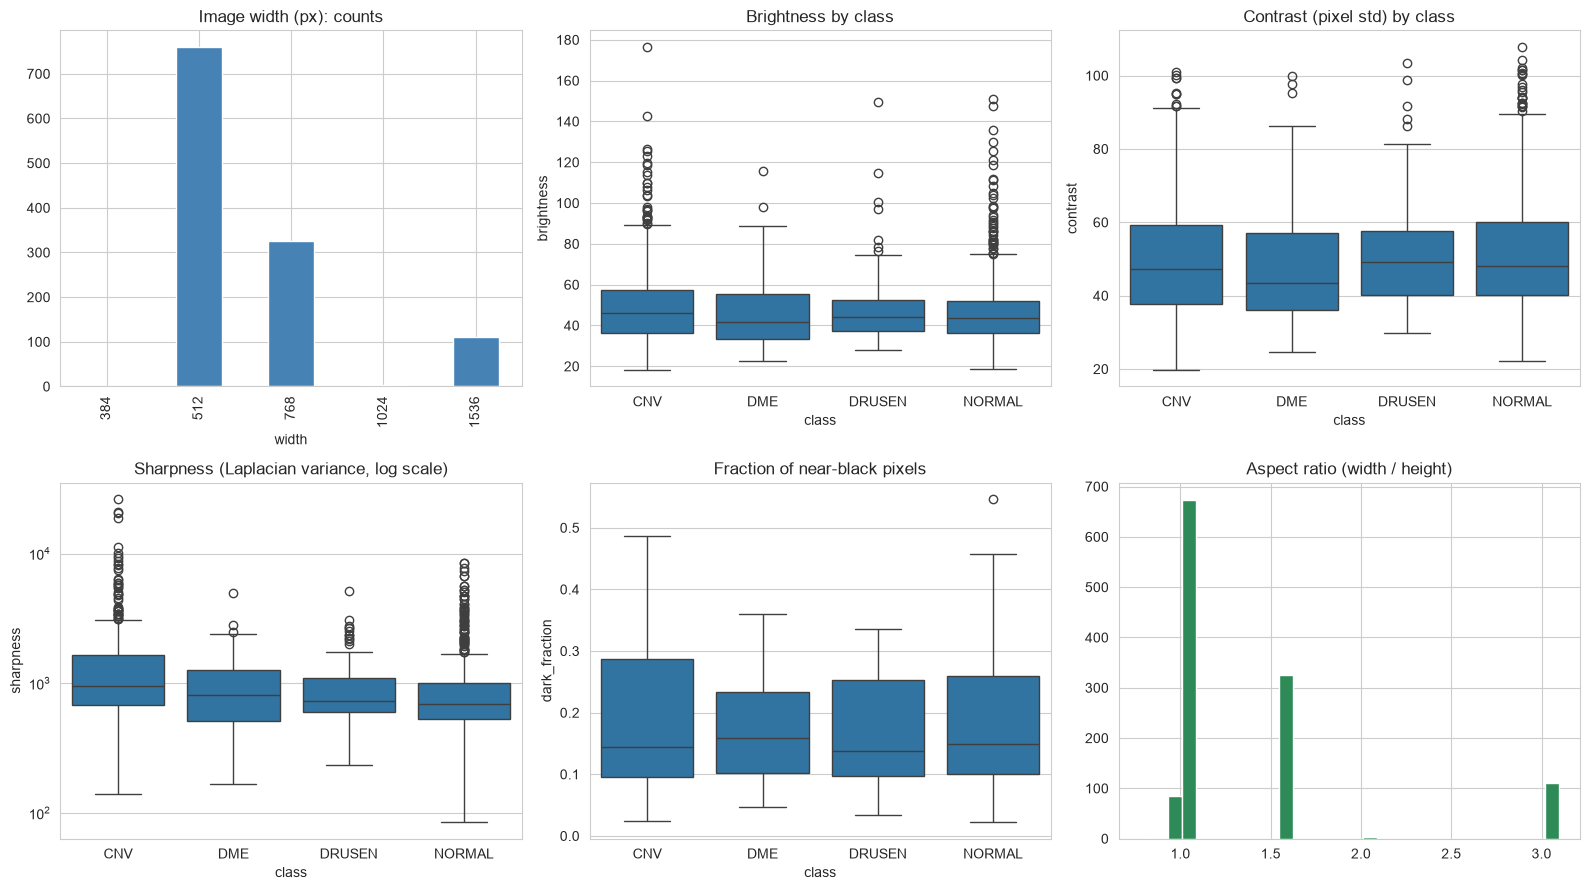

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

stats["width"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Image width (px): counts")

sns.boxplot(data=stats, x="class", y="brightness", order=class_names, ax=axes[0, 1])
axes[0, 1].set_title("Brightness by class")

sns.boxplot(data=stats, x="class", y="contrast", order=class_names, ax=axes[0, 2])
axes[0, 2].set_title("Contrast (pixel std) by class")

sns.boxplot(data=stats, x="class", y="sharpness", order=class_names, ax=axes[1, 0])
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Sharpness (Laplacian variance, log scale)")

sns.boxplot(data=stats, x="class", y="dark_fraction", order=class_names, ax=axes[1, 1])
axes[1, 1].set_title("Fraction of near-black pixels")

axes[1, 2].hist(stats["aspect"], bins=30, color="seagreen")
axes[1, 2].set_title("Aspect ratio (width / height)")

plt.tight_layout()
plt.show()

### Pixel-intensity distribution per class

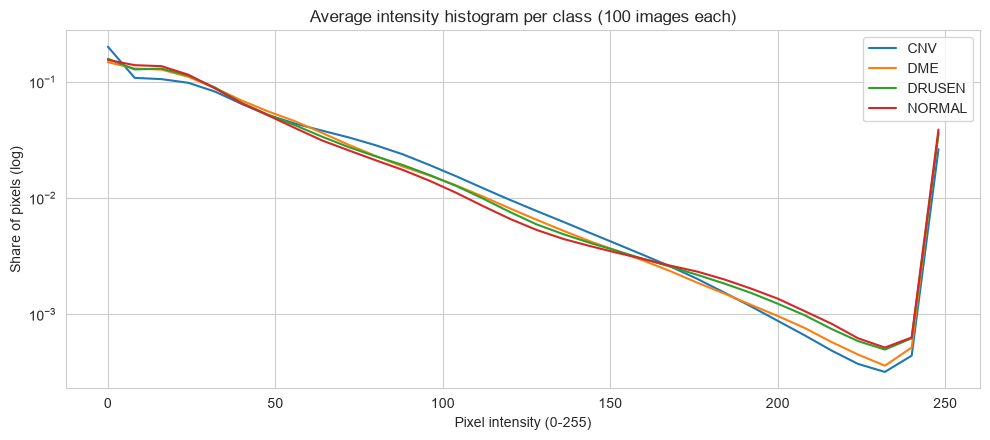

In [8]:
bins = np.arange(0, 257, 8)
plt.figure(figsize=(10, 4.5))
for cname in class_names:
    ids = stats.loc[stats["class"] == cname, "index"].head(100)
    hist = np.zeros(len(bins) - 1)
    for i in ids:
        arr = np.asarray(train_data[int(i)]["image"].convert("L"))
        h, _ = np.histogram(arr, bins=bins)
        hist += h
    plt.plot(bins[:-1], hist / hist.sum(), label=cname)
plt.yscale("log")
plt.xlabel("Pixel intensity (0-255)")
plt.ylabel("Share of pixels (log)")
plt.title("Average intensity histogram per class (100 images each)")
plt.legend()
plt.tight_layout()
plt.show()

### Sharpest vs. blurriest scans in the sample (quality variation)

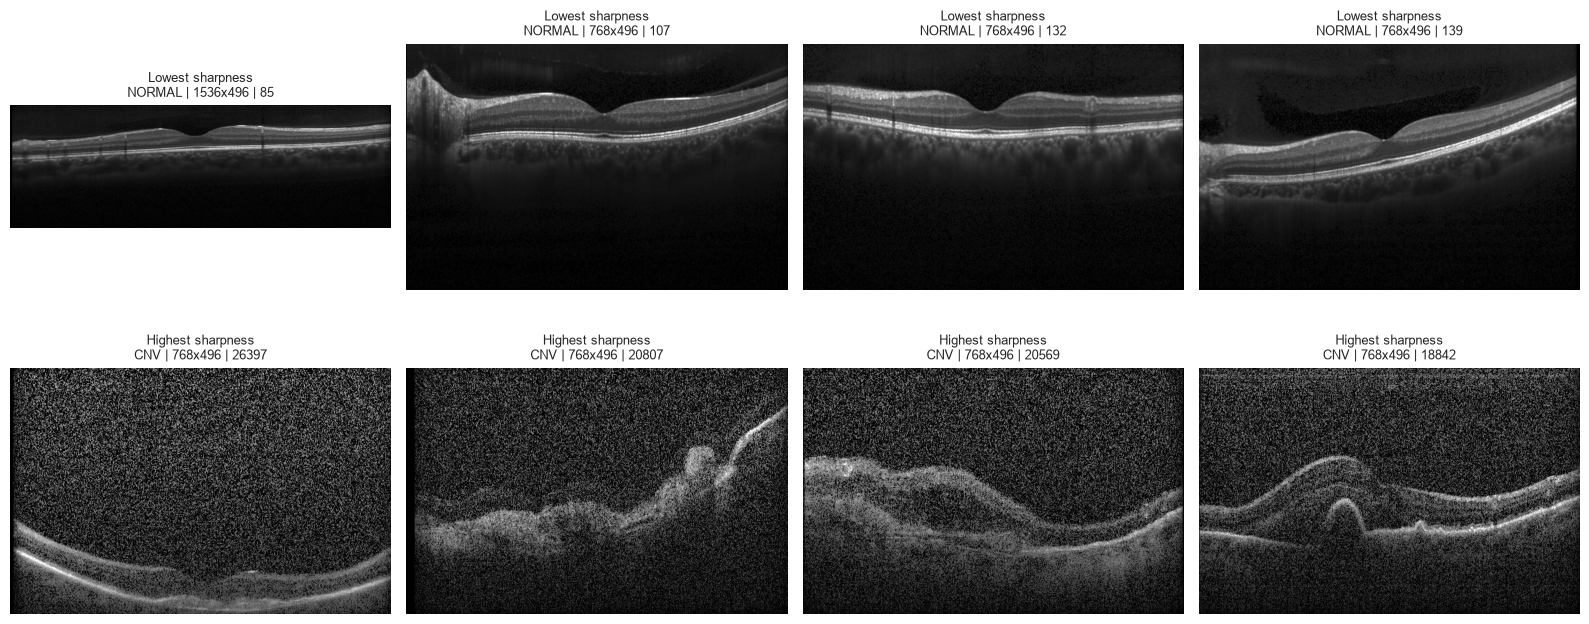

In [9]:
blurry = stats.nsmallest(4, "sharpness")
sharp = stats.nlargest(4, "sharpness")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for row_axes, subset, label in [(axes[0], blurry, "Lowest sharpness"), (axes[1], sharp, "Highest sharpness")]:
    for ax, (_, r) in zip(row_axes, subset.iterrows()):
        ax.imshow(train_data[int(r["index"])]["image"], cmap="gray")
        ax.set_title(f"{label}\n{r['class']} | {r['width']}x{r['height']} | {r['sharpness']:.0f}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

**Results:**
- All images are single-channel (mode `L`), so they need 3 channels only if a pretrained RGB model is used.
- Heights are almost always 496 px, but widths vary (512, 768, 1536), so images must be resized to one size.
- Brightness, contrast and sharpness differ between scans, which is why normalization and mild brightness/contrast augmentation help.

In [ ]:
## 2.3 Resize images to a consistent dimension
Resize to **224 x 224**, the standard input size for ResNet, DenseNet, EfficientNet and similar pretrained models. 
Change `IMG_SIZE` if you want a different size.
Wide scans (1536 px) get squeezed horizontally more than 512 px ones, so we check that the retinal layers are still recognisable.

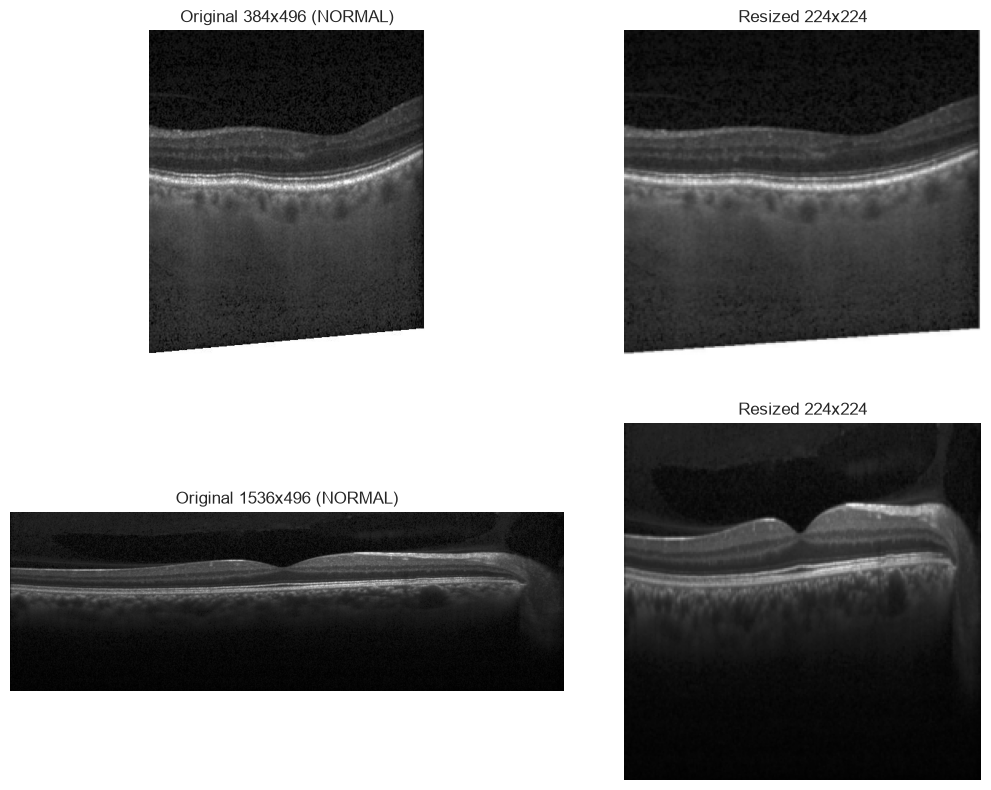

In [10]:
IMG_SIZE = 224
resize = T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BILINEAR, antialias=True)

narrow = stats.loc[stats["width"] == stats["width"].min()].iloc[0]
wide = stats.loc[stats["width"] == stats["width"].max()].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for r, rec in enumerate([narrow, wide]):
    img = train_data[int(rec["index"])]["image"]
    axes[r, 0].imshow(img, cmap="gray")
    axes[r, 0].set_title(f"Original {img.width}x{img.height} ({rec['class']})")
    axes[r, 1].imshow(resize(img), cmap="gray")
    axes[r, 1].set_title(f"Resized {IMG_SIZE}x{IMG_SIZE}")
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout()
plt.show()

## 2.4 Convert images into tensors
`ToTensor()` converts a PIL image (H x W, 0-255) into a float tensor (C x H x W, 0-1). We first use `Grayscale(num_output_channels=3)` to repeat the grey channel three times, matching pretrained RGB models. For a custom one-channel CNN, set `num_output_channels=1`.

In [11]:
to_3ch = T.Grayscale(num_output_channels=3)
to_tensor = T.ToTensor()

img = train_data[0]["image"]
x = to_tensor(to_3ch(resize(img)))

print("Tensor shape:", tuple(x.shape), "(C, H, W)")
print("dtype:", x.dtype)
print(f"value range: {x.min().item():.3f} to {x.max().item():.3f}")

Tensor shape: (3, 224, 224) (C, H, W)
dtype: torch.float32
value range: 0.004 to 1.000


In [ ]:
## 2.5 Normalization
Compute the grey-level mean and standard deviation of our own data on a random sample (at the resized resolution), and compare with 
ImageNet statistics. Pretrained models expect ImageNet statistics, so that is the default. Switch the flag to use the dataset's own.

In [12]:
def estimate_mean_std(n=2000):
    idx = rng.choice(len(train_data), n, replace=False)
    s = s2 = 0.0
    count = 0
    for i in idx:
        arr = np.asarray(resize(train_data[int(i)]["image"].convert("L")), dtype=np.float64) / 255.0
        s += arr.sum()
        s2 += (arr ** 2).sum()
        count += arr.size
    mean = s / count
    return mean, float(np.sqrt(s2 / count - mean ** 2))

ds_mean, ds_std = estimate_mean_std(2000)
print(f"Dataset grey-level mean = {ds_mean:.4f}, std = {ds_std:.4f}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

USE_IMAGENET_STATS = True      # True for pretrained models; False to use the dataset's own statistics

if USE_IMAGENET_STATS:
    NORM_MEAN, NORM_STD = IMAGENET_MEAN, IMAGENET_STD
else:
    NORM_MEAN, NORM_STD = [ds_mean] * 3, [ds_std] * 3

print("Using mean:", NORM_MEAN, "std:", NORM_STD)

Dataset grey-level mean = 0.1909, std = 0.2169
Using mean: [0.485, 0.456, 0.406] std: [0.229, 0.224, 0.225]


## 2.6 Data augmentation
Augmentation is applied **only to training data**. Choices for OCT scans:

| Technique | Setting | Why |
|---|---|---|
| Horizontal flip | p = 0.5 | A flipped scan is still anatomically plausible |
| Small rotation | up to 10 degrees | Patient head tilt and scan angle vary |
| Small shift and zoom | 5% shift, 0.9-1.1 scale | Fovea position varies |
| Brightness / contrast | +/- 20% | Scanner and exposure variation seen in 2.2 |
| **No vertical flip** | n/a | Retinal layers have a fixed top-to-bottom order; flipping would create unrealistic images |

Resizing comes first. Cropping a square region from a very wide scan before resizing would throw away much of the retina.

In [13]:
aug_ops = [
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
]

train_tf = T.Compose(aug_ops + [T.ToTensor(), T.Normalize(NORM_MEAN, NORM_STD)])

eval_tf = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    T.ToTensor(),
    T.Normalize(NORM_MEAN, NORM_STD),
])

print("Train transform:\n", train_tf)
print("\nEval transform:\n", eval_tf)

Train transform:
 Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.9, 1.1))
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Eval transform:
 Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Preview: original and augmented versions (one row per class)

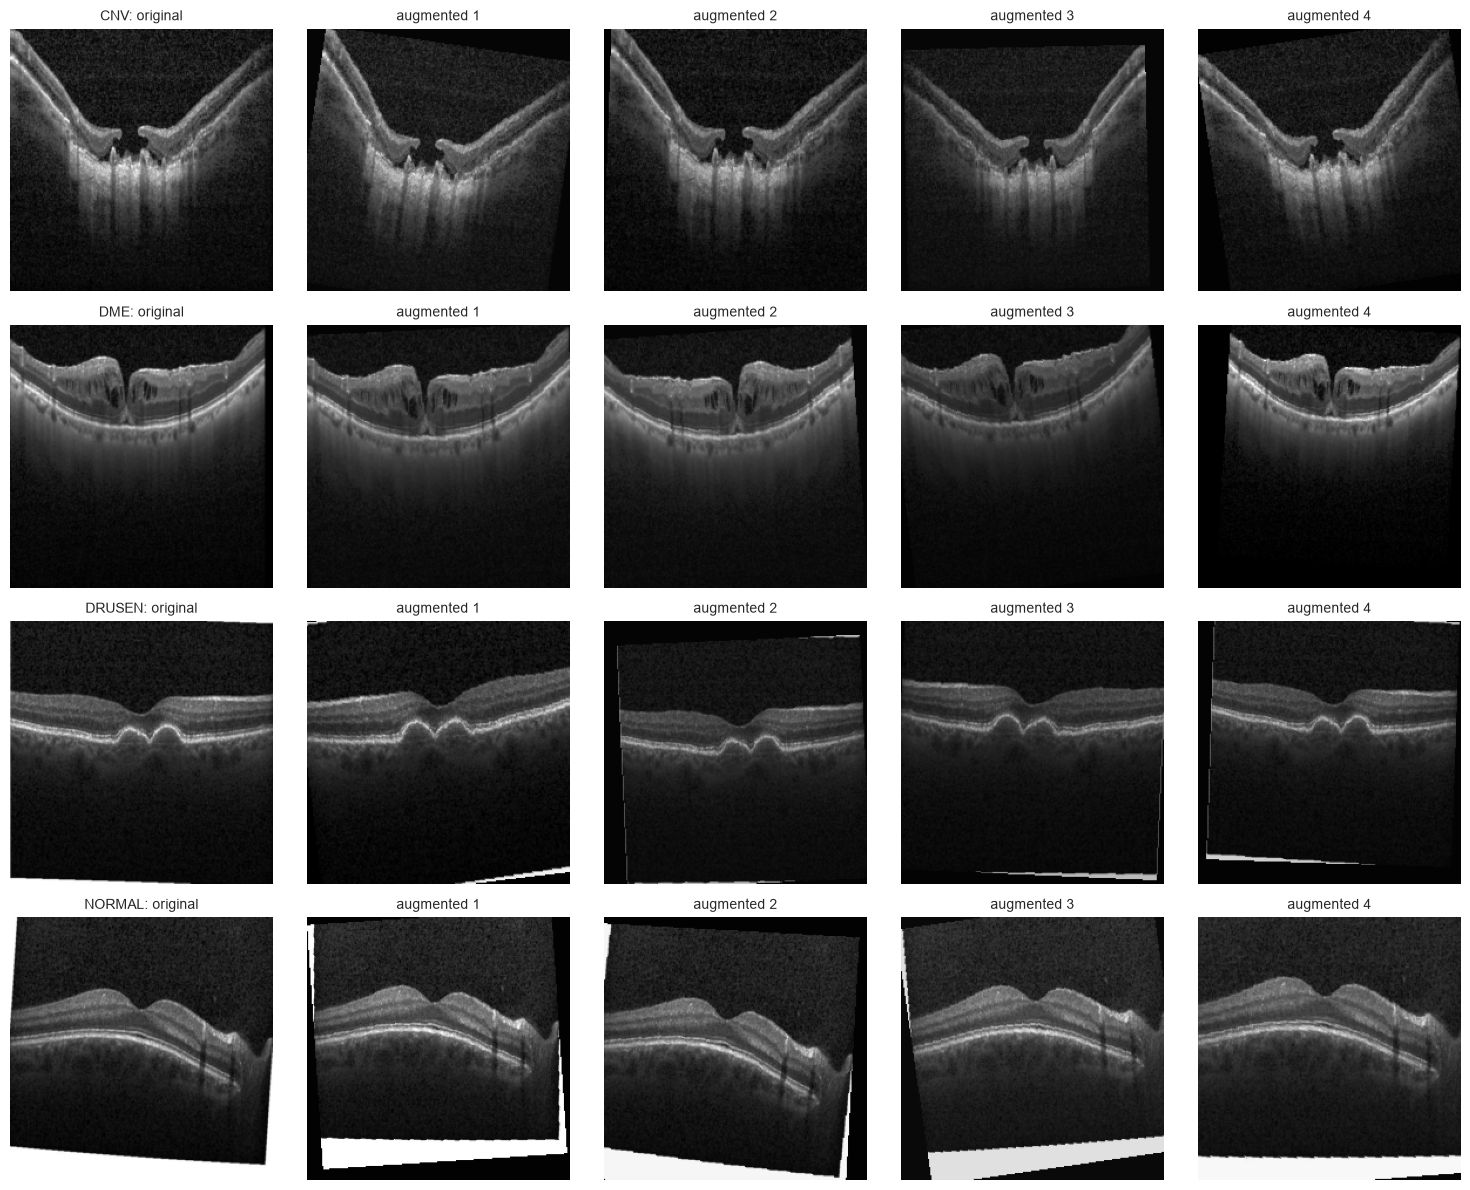

In [14]:
preview_tf = T.Compose(aug_ops)
N_AUG = 4

fig, axes = plt.subplots(len(class_names), N_AUG + 1, figsize=(3 * (N_AUG + 1), 3 * len(class_names)))
for r, cname in enumerate(class_names):
    i = int(rng.choice(np.where(train_labels == r)[0]))
    img = train_data[i]["image"]
    axes[r, 0].imshow(resize(img), cmap="gray")
    axes[r, 0].set_title(f"{cname}: original", fontsize=10)
    for c in range(1, N_AUG + 1):
        axes[r, c].imshow(preview_tf(img))
        axes[r, c].set_title(f"augmented {c}", fontsize=10)
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 2.7 CONCLUSION: datasets and DataLoaders
- The test split is kept untouched.
- A validation set (10%) is cut from training, **stratified by class**.
- Transforms are applied on the fly, with training augmentation for train and none for validation/test.

> **Caution:** the original dataset labels images with patient IDs, but this Hugging Face copy does not expose them. A random validation split could share patients with training, so validation scores may look better than they really are. The official test set is patient-independent, so trust it for the final number.

In [15]:
split = train_data.train_test_split(test_size=0.10, stratify_by_column="label", seed=SEED)
train_split, val_split = split["train"], split["test"]

def make_transform(tf):
    def _apply(batch):
        return {
            "pixel_values": [tf(img.convert("L")) for img in batch["image"]],
            "labels": batch["label"],
        }
    return _apply

train_ds = train_split.with_transform(make_transform(train_tf))
val_ds = val_split.with_transform(make_transform(eval_tf))
test_ds = test_data.with_transform(make_transform(eval_tf))

def collate_fn(batch):
    x = torch.stack([b["pixel_values"] for b in batch])
    y = torch.tensor([b["labels"] for b in batch], dtype=torch.long)
    return x, y

BATCH_SIZE = 32
# num_workers=0 avoids multiprocessing problems on Windows / Jupyter
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, collate_fn=collate_fn)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, collate_fn=collate_fn)

print(f"train: {len(train_ds):,} | val: {len(val_ds):,} | test: {len(test_ds):,}")

train: 97,478 | val: 10,831 | test: 1,000


### Sanity check on one batch

Batch images: (32, 3, 224, 224) torch.float32
Batch labels: (32,) torch.int64
Normalized value range: -2.12 to 2.64 | mean -1.184 | std 1.015
Labels in batch: {'CNV': 10, 'DME': 3, 'DRUSEN': 2, 'NORMAL': 17}


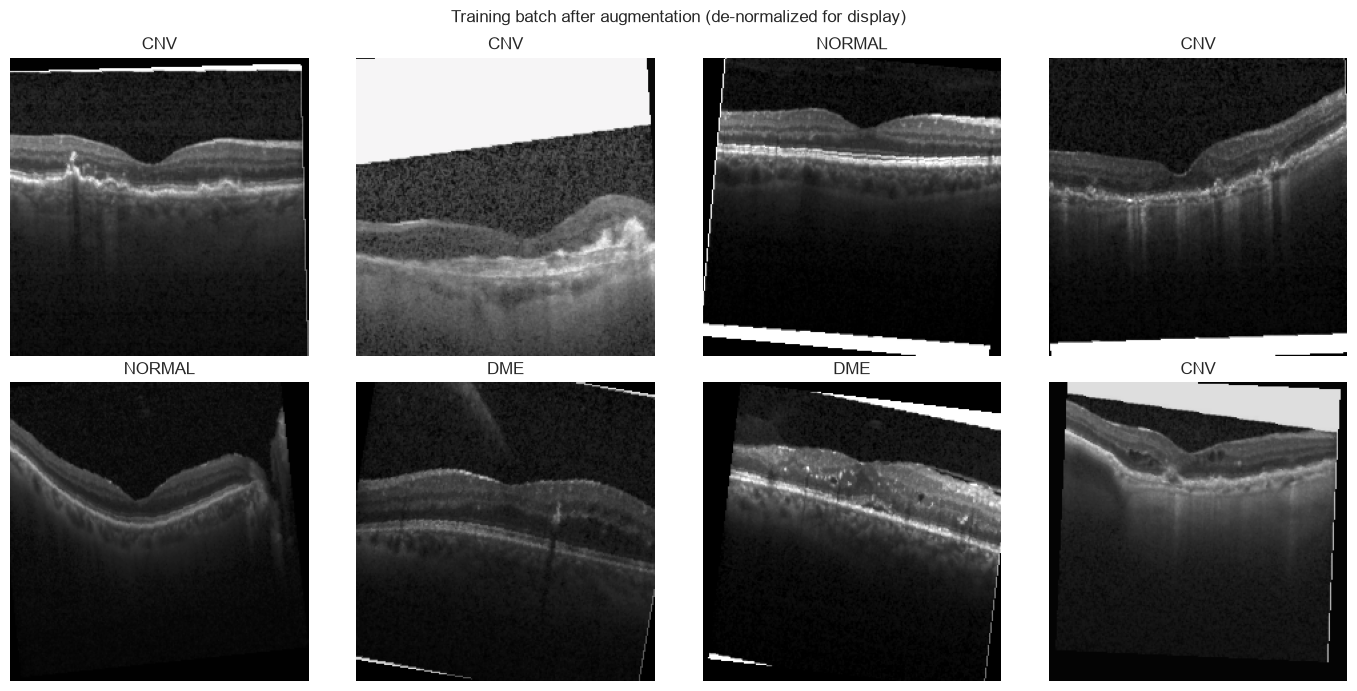

In [16]:
xb, yb = next(iter(train_loader))
print("Batch images:", tuple(xb.shape), xb.dtype)
print("Batch labels:", tuple(yb.shape), yb.dtype)
print(f"Normalized value range: {xb.min():.2f} to {xb.max():.2f} | mean {xb.mean():.3f} | std {xb.std():.3f}")
print("Labels in batch:", {class_names[k]: int(v) for k, v in zip(*np.unique(yb.numpy(), return_counts=True))})

mean_t = torch.tensor(NORM_MEAN).view(3, 1, 1)
std_t = torch.tensor(NORM_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img_t, lab in zip(axes.ravel(), xb[:8], yb[:8]):
    ax.imshow((img_t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(class_names[int(lab)])
    ax.axis("off")
plt.suptitle("Training batch after augmentation (de-normalized for display)")
plt.tight_layout()
plt.show()

### Save the preprocessing settings for later steps

In [17]:
config = {
    "dataset_id": "zacharielegault/Kermany2017-OCT",
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "norm_mean": NORM_MEAN,
    "norm_std": NORM_STD,
    "val_fraction": 0.10,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
}
with open("preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved preprocessing_config.json")

Saved preprocessing_config.json


## Summary of Step 2
- Visualized scans from all four classes and checked size, brightness, contrast and sharpness variation.
- Resized every image to 224 x 224, converted to tensors (3-channel) and normalized.
- Built training augmentation suited to OCT (horizontal flip, small rotation/shift/zoom, mild brightness/contrast, no vertical flip).
- Created stratified train/validation splits and DataLoaders; the test set is untouched.
